In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glob import glob
from copy import deepcopy

from astropy.io import fits
from astropy.wcs import WCS

from reproject import reproject_interp
from reproject.mosaicking import find_optimal_celestial_wcs

from AstroColour.AstroColour import RGB

# epoch_colour_utils.py must be in the same folder as this notebook
sys.path.append('.')
# from epoch_colour_utils import assign_epochs, build_epoch_images, make_colour_cube

%matplotlib widget

In [2]:
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

inches_per_pt   = 1.0 / 72.27
text_width_pt   = 508.0          # \the\textwidth in your LaTeX document
fig_width_full  = text_width_pt * inches_per_pt * 1.5

In [3]:
image_folder = '/Users/zalane/Desktop/JWST-MIRI-2023dbc/MAST/JWST/'

image_files = glob(image_folder + '*.fits')

image_files

['/Users/zalane/Desktop/JWST-MIRI-2023dbc/MAST/JWST/jw03921-o039_t041_miri_f2100w_i2d.fits',
 '/Users/zalane/Desktop/JWST-MIRI-2023dbc/MAST/JWST/jw03921-o039_t041_miri_f770w_i2d.fits',
 '/Users/zalane/Desktop/JWST-MIRI-2023dbc/MAST/JWST/jw03921-o039_t041_miri_f1500w_i2d.fits',
 '/Users/zalane/Desktop/JWST-MIRI-2023dbc/MAST/JWST/jw03921-o039_t041_miri_f1000w_i2d.fits']

F2100W


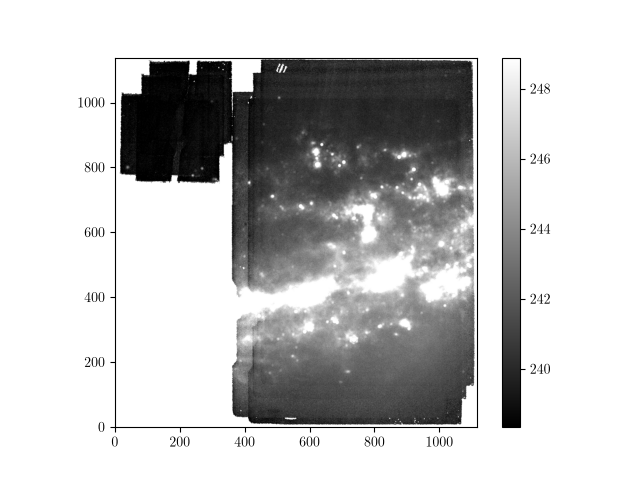

F770W


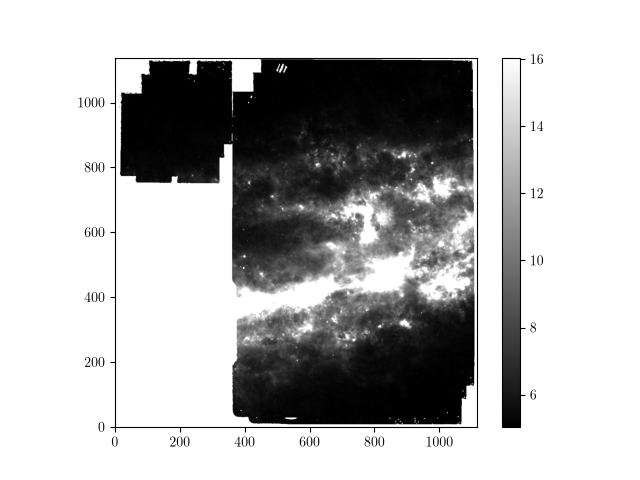

F1500W


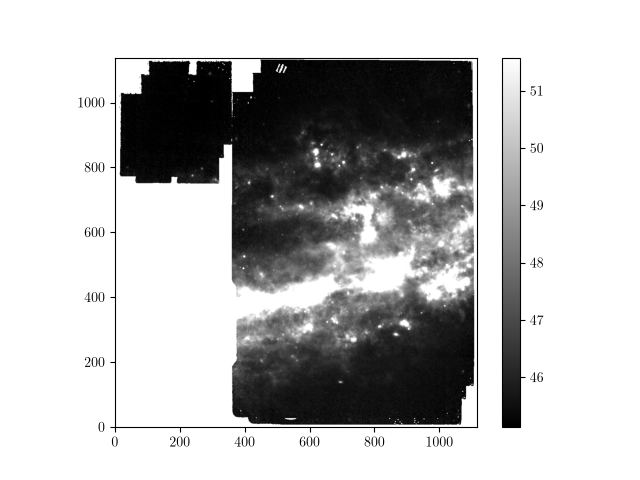

F1000W


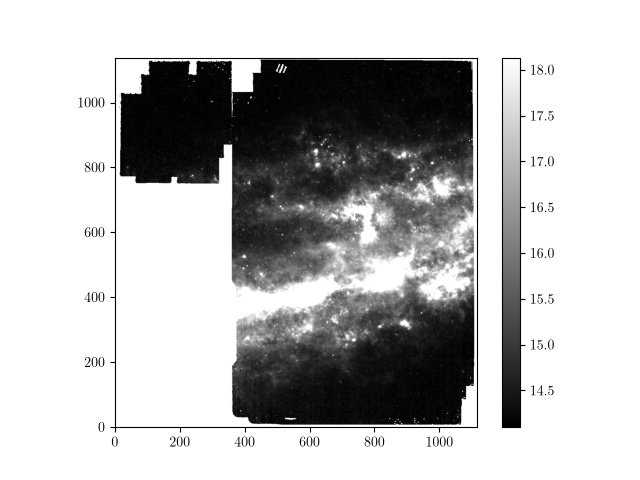

Pixel coordinates of the target: x=777.464441608012, y=599.4136360991682


In [5]:
ra = 167.913458
dec = 55.674719

filter_list = []
colour_cube = []

for i, image in enumerate(image_files):
    hdulist = fits.open(image)
    header = hdulist[0].header
    wcs = WCS(hdulist[1].header)
    data = hdulist[1].data
    
    if i == 0:
        master_wcs = deepcopy(wcs)
        shape_out = data.shape
        # master_wcs, shape_out = find_optimal_celestial_wcs((data, wcs), frame='icrs', auto_rotate=False)
        reprojected_data, footprint = reproject_interp((data, wcs), master_wcs, shape_out=shape_out)
    if i != 0:
        # master_wcs, shape_out = find_optimal_celestial_wcs(hdulist, frame='icrs', auto_rotate=False)
        reprojected_data, footprint = reproject_interp((data, wcs), master_wcs, shape_out=shape_out)
    
    print(header['FILTER'])
    filter_list.append(header['FILTER'])
    
    plt.figure()
    plt.imshow(reprojected_data, cmap='gray', origin='lower', vmin = np.nanpercentile(reprojected_data, 5), vmax = np.nanpercentile(reprojected_data, 95))
    plt.colorbar()
    plt.show()
    
    colour_cube.append(reprojected_data)
    
x1, y1 = master_wcs.all_world2pix(ra, dec, 0)
print(f"Pixel coordinates of the target: x={x1}, y={y1}")

In [6]:
channel_filters = {'purple': 'F770W', 'blue': 'F1000W', 'green': 'F1500W', 'red': 'F2100W'}

for i, key in enumerate(channel_filters):
    v = channel_filters[key]
    print(f"{i}: {key} -> {v}")
    idx = filter_list.index(v)
    print(f"Index in filter_list: {idx}")
    # print(filter_list[i])

new_colour_cube = [colour_cube[filter_list.index(channel_filters[key])] for i, key in enumerate(channel_filters)]

0: purple -> F770W
Index in filter_list: 1
1: blue -> F1000W
Index in filter_list: 3
2: green -> F1500W
Index in filter_list: 2
3: red -> F2100W
Index in filter_list: 0


In [7]:
rgb = RGB(new_colour_cube,
          save=False, save_name='colour_image', save_folder='.',
          epsf_plot=False, epsf=False,
          bkg_plot=False, temp_save=True, run=False, manual_override=0)

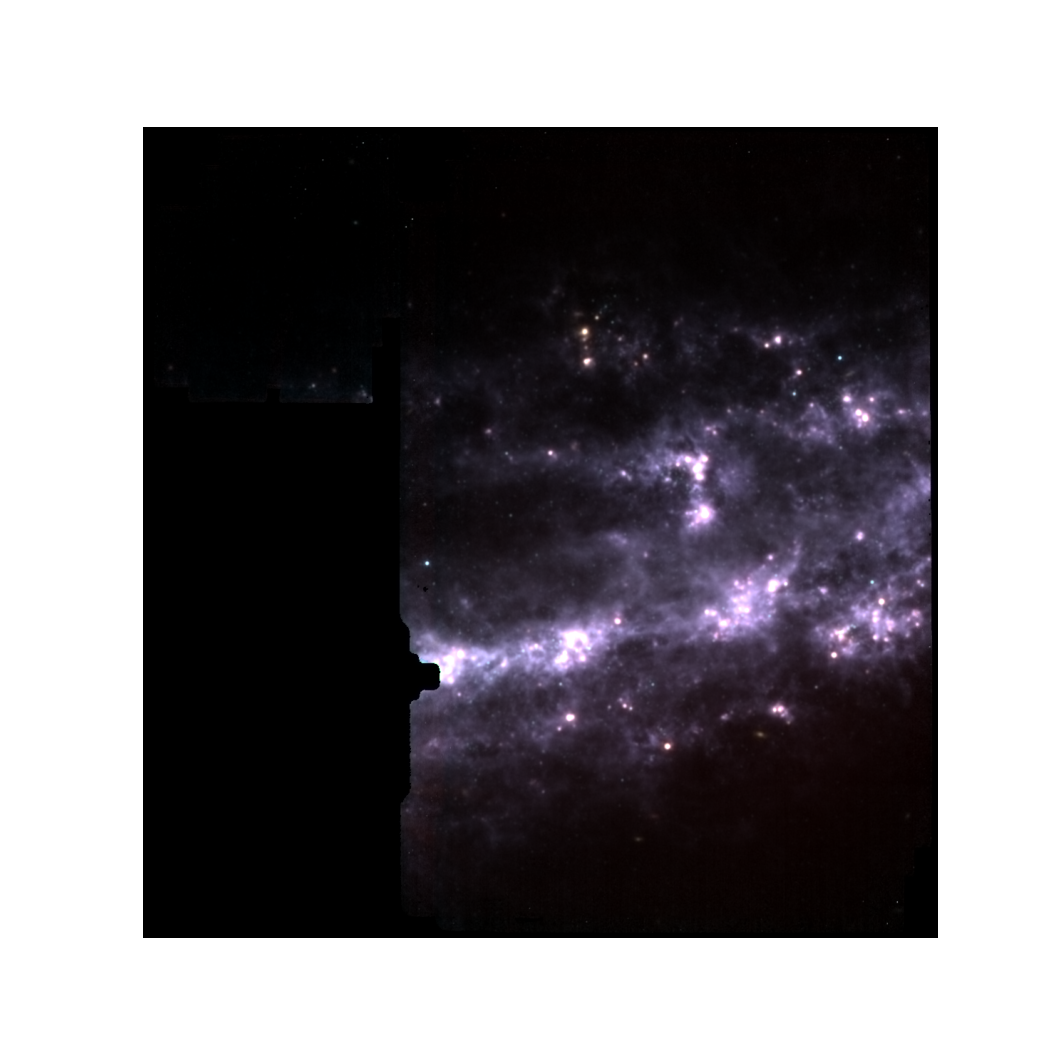

In [16]:
colour = rgb.master_plot(new_colour_cube,
                          colours=None,
                          intensities=[0.9, 1.2, 1.2, 0.9],
                          gamma=[1, 1, 1, 1],
                          norms=['asinh', 'asinh', 'asinh', 'asinh'],   # unused by asinh_sigma, harmless to leave
                          uppers=[99.9999, 99.9999, 99.9999, 99.9999],        # white-point percentile
                          lowers=[10, 10, 10, 10],              # black point, in noise-sigma
                          cmap_choice='rainbow',
                          interactive=False,
                          method='percent',#'asinh_sigma',
                          chroma_denoise_final=True)

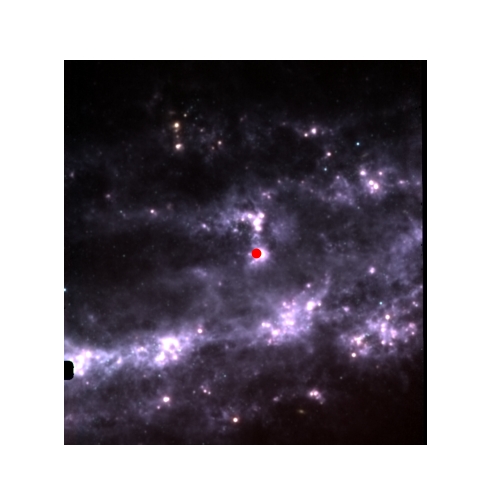

In [17]:
plt.figure(figsize=(5, 5))
plt.imshow(colour, origin='lower')
plt.scatter(x1, y1, color = 'r')
plt.axis('off')
plt.xlim(x1 - 380, x1 + 380)
plt.ylim(y1 - 380, y1 + 380)
plt.show()
